# Bloc C : adaptation QLoRA du tuteur (résumé de lecture)

- **Le tuteur** reçoit une fiche de cours, une question et la réponse d'un élève. Il répond par un verdict (`PARFAIT`, `PARTIEL`, `INCORRECT` ou `HORS_PERIMETRE`), puis par un feedback.
- **Ce notebook** montre ce que le modèle apprend, ce que l'adaptation change, pourquoi on s'arrête à ce moment de l'entraînement et pourquoi ces réglages.
- **Il se lit sans rien relancer** : les résultats sont déjà affichés. Il ne charge pas le modèle ; il lit des fichiers du dépôt (données, [`results/`](results/)) et utilise seulement le tokenizer. Il ne remplace pas le notebook final du projet.
- **Le code** : `src/training/` (entraînement, évaluation, courbes). Les commandes pour tout refaire sont à la fin.

In [1]:
import csv, json, sys, warnings
from pathlib import Path
from IPython.display import Markdown, Image, display

warnings.filterwarnings("ignore")  # avertissements de bibliothèques, sans intérêt pour la lecture
RUN = "train_v0.3"  # dossier de experiments/results/ ; à remplacer par train_v1.0 quand le run final sera copié dans le dépôt
EVAL_BASE = "eval/eval_v0.3_base.json"  # idem : remplacés automatiquement par eval_v1.0_*.json s'ils existent
EVAL_LORA = "eval/eval_v0.3_lora.json"
FINAL_PLAN = {"eval_every": 25, "patience": 4}  # réglages du run final ; relus dans son config.json dès qu'il existe
# on remonte jusqu'au dossier qui contient src/training : le notebook marche depuis experiments/ ou depuis la racine
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "training").is_dir())
sys.path.insert(0, str(ROOT))
RESULTS = ROOT / "experiments" / "results"
if all((RESULTS / f"eval/eval_v1.0_{m}.json").exists() for m in ("base", "lora")):
    EVAL_BASE, EVAL_LORA = "eval/eval_v1.0_base.json", "eval/eval_v1.0_lora.json"
if (RESULTS / "train_v1.0" / "config.json").exists():
    final_cfg = json.loads((RESULTS / "train_v1.0" / "config.json").read_text(encoding="utf-8"))
    FINAL_PLAN.update({k: v for k, v in final_cfg.items() if k in FINAL_PLAN})
print(f"entraînement lu : experiments/results/{RUN}")
print(f"évaluation lue  : experiments/results/{EVAL_BASE} et {Path(EVAL_LORA).name}")

entraînement lu : experiments/results/train_v0.3
évaluation lue  : experiments/results/eval/eval_v0.3_base.json et eval_v0.3_lora.json


In [2]:
from src.training.dataset import load_split

n_train = len(load_split("train"))
display(Markdown(f"""### En deux mots

`fiche + question + réponse de l'élève`  →  `Qwen2.5-3B (gelé) + adaptateur LoRA`  →  `[VERDICT: X] + feedback`

Qwen a 3 milliards de poids ; on n'y touche pas (ils sont gelés). On branche un petit module de quelques dizaines de Mo, l'adaptateur (LoRA), et seul lui est entraîné. QLoRA : en plus, le modèle gelé est stocké en 4 bits pour tenir en mémoire.

- **loss** : erreur moyenne du modèle, token par token, sur la réponse attendue du tuteur. Plus elle est basse, plus il écrit comme le dataset.
- **epoch** : un passage sur les {n_train} exemples d'entraînement.
- **pas** : une correction de l'adaptateur.
- **lot** : nombre de conversations passées ensemble avant chaque correction.
- **HORS_PERIMETRE** : la réponse de l'élève sort du sujet de la fiche. Le tuteur doit refuser de la noter et recadrer."""))

### En deux mots

`fiche + question + réponse de l'élève`  →  `Qwen2.5-3B (gelé) + adaptateur LoRA`  →  `[VERDICT: X] + feedback`

Qwen a 3 milliards de poids ; on n'y touche pas (ils sont gelés). On branche un petit module de quelques dizaines de Mo, l'adaptateur (LoRA), et seul lui est entraîné. QLoRA : en plus, le modèle gelé est stocké en 4 bits pour tenir en mémoire.

- **loss** : erreur moyenne du modèle, token par token, sur la réponse attendue du tuteur. Plus elle est basse, plus il écrit comme le dataset.
- **epoch** : un passage sur les 885 exemples d'entraînement.
- **pas** : une correction de l'adaptateur.
- **lot** : nombre de conversations passées ensemble avant chaque correction.
- **HORS_PERIMETRE** : la réponse de l'élève sort du sujet de la fiche. Le tuteur doit refuser de la noter et recadrer.

## 1. Ce que le modèle apprend

Le modèle reçoit la fiche, la question et la réponse d'un élève. Il doit répondre par un verdict, puis par un feedback qui aide sans donner la réponse.
Il apprend trois choses : le **format** (le verdict d'abord), le **jugement** (comparer la réponse à la fiche) et le **refus** (verdict `HORS_PERIMETRE` quand la réponse sort du sujet).
Il n'apprend pas le contenu des fiches : il est déjà dans le prompt.

In [3]:
from transformers import AutoTokenizer
from src.training.dataset import load_split

tokenizer = AutoTokenizer.from_pretrained("Qwen/Qwen2.5-3B-Instruct")  # le tokenizer seul, pas le modèle
system, student, tutor = load_split("train")[0]  # une conversation = fiche + question, réponse de l'élève, réponse du tuteur
n_system = len(tokenizer(system["content"], add_special_tokens=False)["input_ids"])
print("--- prompt système (début) ---")
print(system["content"].split("COURS ACCESSIBLE")[0] + "COURS ACCESSIBLE AVANT CETTE QUESTION :")
print("[… la fiche du cours, la grille et les règles, longues, sont masquées ici …]")
print(f"(le prompt système fait {n_system} tokens, dont la fiche)")
print("\n--- message de l'élève ---")
print(student["content"])
print("\n--- réponse du tuteur (ce que le modèle doit produire) ---")
print(tutor["content"])

--- prompt système (début) ---
Tu es Brainmaxxing, un tuteur qui évalue la réponse d'un étudiant.
Applique la grille propre à la QUESTION ACTUELLE ; n'impose pas ta propre opinion.

CONCEPT : L'identité à travers le changement (identité personnelle)
MATIÈRE : philosophie
QUESTION ACTUELLE : Ce bateau, dont toutes les planches ont été remplacées, est-il encore le bateau de Thésée ? Réponds oui ou non, puis surtout : qu'est-ce qui, selon toi, fait qu'un objet reste « le même » ? Essaie de formuler ta règle en une phrase.
COURS ACCESSIBLE AVANT CETTE QUESTION :
[… la fiche du cours, la grille et les règles, longues, sont masquées ici …]
(le prompt système fait 1524 tokens, dont la fiche)

--- message de l'élève ---
RÉPONSE ACTUELLE À ÉVALUER :
Non. Pour moi un objet c'est sa matière, et là il ne reste plus une seule planche d'origine, donc ce qui est au port c'est une réplique.

--- réponse du tuteur (ce que le modèle doit produire) ---
[VERDICT: PARFAIT]
Net et sans détour. Tu poses ton 

In [4]:
import collections
from src.training.dataset import DATA_DIR, IGNORE_INDEX, token_lengths, tokenize_example

with open(DATA_DIR / "dataset_source.csv", encoding="utf-8-sig", newline="") as file:
    source_rows = list(csv.DictReader(file, delimiter=";"))
for split in ("train", "val"):
    counts = collections.Counter(r["label"] for r in source_rows if r["split"] == split)
    print(f"{split:5} ({sum(counts.values())} exemples) : " + ", ".join(f"{label} {counts[label]}" for label in ("PARFAIT", "PARTIEL", "INCORRECT", "HORS_PERIMETRE")))

conversations = load_split("train") + load_split("val")
print(f"\nconversation la plus longue : {max(token_lengths(conversations, tokenizer))} tokens")
encoded = tokenize_example(load_split("train")[0], tokenizer)
learned = sum(label != IGNORE_INDEX for label in encoded["labels"])
masked = len(encoded["labels"]) - learned
print(f"exemple ci-dessus : {learned} tokens appris (réponse du tuteur), {masked} masqués (prompt), dont {n_system} pour le prompt système ({n_system / masked:.0%})")
print("Seule la réponse du tuteur compte dans la loss.")

train (885 exemples) : PARFAIT 240, PARTIEL 240, INCORRECT 240, HORS_PERIMETRE 165
val   (118 exemples) : PARFAIT 32, PARTIEL 32, INCORRECT 32, HORS_PERIMETRE 22



conversation la plus longue : 3638 tokens
exemple ci-dessus : 56 tokens appris (réponse du tuteur), 1589 masqués (prompt), dont 1524 pour le prompt système (96%)
Seule la réponse du tuteur compte dans la loss.


### Ce que ça change

Même jeu `val`, deux modèles : le modèle de base (sans adaptateur) et le modèle avec l'adaptateur LoRA. Les mesures sont calculées à partir des deux JSON d'évaluation.

- **Verdict juste** = exactitude : la part des verdicts égaux au verdict attendu.
- **Erreur grave** : un INCORRECT ou un HORS_PERIMETRE attendu que le modèle note PARFAIT (il valide ce qu'il aurait dû corriger ou refuser).

In [5]:
from src.training.dataset import DATA_DIR

def read_eval(name):
    """Lit un JSON d'évaluation et en tire les quatre mesures du tableau."""
    data = json.loads((RESULTS / name).read_text(encoding="utf-8"))
    rows = data["rows"]
    refus = [r for r in rows if r["expected"] == "HORS_PERIMETRE"]
    graves = [r for r in rows if r["expected"] in ("INCORRECT", "HORS_PERIMETRE")]
    return [f"{data['accuracy']:.0%}", f"{round(data['valid_format_rate'] * len(rows))} / {len(rows)}",
            f"{sum(r['predicted'] == 'HORS_PERIMETRE' for r in refus)} / {len(refus)}",
            f"{sum(r['predicted'] == 'PARFAIT' for r in graves)} / {len(graves)}"], len(rows)

base, n_val = read_eval(EVAL_BASE)
lora, _ = read_eval(EVAL_LORA)
with open(DATA_DIR / "dataset_source.csv", encoding="utf-8-sig", newline="") as file:
    n_questions = len({r["question_id"] for r in csv.DictReader(file, delimiter=";") if r["split"] == "val"})
display(Markdown(f"> **Limite.** `val` ne contient que {n_questions} questions et {n_val} exemples très corrélés, et il a servi à choisir l'adaptateur retenu. Ces chiffres sont optimistes. Le test indépendant est celui du bloc d'évaluation, pas encore fusionné."))
noms = ["Verdict juste (exactitude)", "Format valide", "HORS_PERIMETRE détectés (trouvés / attendus)", "Erreurs graves (définition ci-dessus)"]
display(Markdown("| Mesure | Base | LoRA |\n|---|---|---|\n" + "\n".join(f"| {n} | {b} | {l} |" for n, b, l in zip(noms, base, lora))))

> **Limite.** `val` ne contient que 2 questions et 118 exemples très corrélés, et il a servi à choisir l'adaptateur retenu. Ces chiffres sont optimistes. Le test indépendant est celui du bloc d'évaluation, pas encore fusionné.

| Mesure | Base | LoRA |
|---|---|---|
| Verdict juste (exactitude) | 49% | 92% |
| Format valide | 105 / 118 | 118 / 118 |
| HORS_PERIMETRE détectés (trouvés / attendus) | 0 / 22 | 21 / 22 |
| Erreurs graves (définition ci-dessus) | 6 / 54 | 0 / 54 |

In [6]:
files = sorted(RESULTS.glob("exemples_*.json")) + sorted((RESULTS / "eval").glob("exemples_*.json"))
if not files:
    display(Markdown("*Exemples côte à côte : à ajouter après l'export sur Colab, voir `src/training/export_examples.py`.*"))
else:
    def cell(text, size=260):
        """Texte court, sûr dans une cellule de tableau Markdown."""
        text = text if len(text) <= size else text[:size] + "…"
        return text.replace("|", "\\|").replace("\n", " ")

    cases = json.loads(files[-1].read_text(encoding="utf-8"))["cases"]
    out = [f"Exemples lus dans `{files[-1].name}`.\n", "| Attendu | Élève | Base | LoRA | Raison |", "|---|---|---|---|---|"]
    for c in cases:
        out.append(f"| {c['verdict_attendu']} | {cell(c['reponse_eleve'])} | {cell(c['base']['texte'])} | {cell(c['lora']['texte'])} | {c['raison']} |")
    display(Markdown("\n".join(out)))

*Exemples côte à côte : à ajouter après l'export sur Colab, voir `src/training/export_examples.py`.*

## 2. Pourquoi on s'arrête là

Sur les exemples d'entraînement, la loss baisse à chaque epoch. Sur `val` (des exemples jamais vus), elle baisse puis remonte : c'est un signe de surapprentissage (le modèle colle de plus en plus à ses exemples d'entraînement).
On garde donc l'adaptateur du meilleur moment, pas celui de la fin.

courbe par epoch enregistrée dans experiments/results/courbe_resume_train_v0.3.png


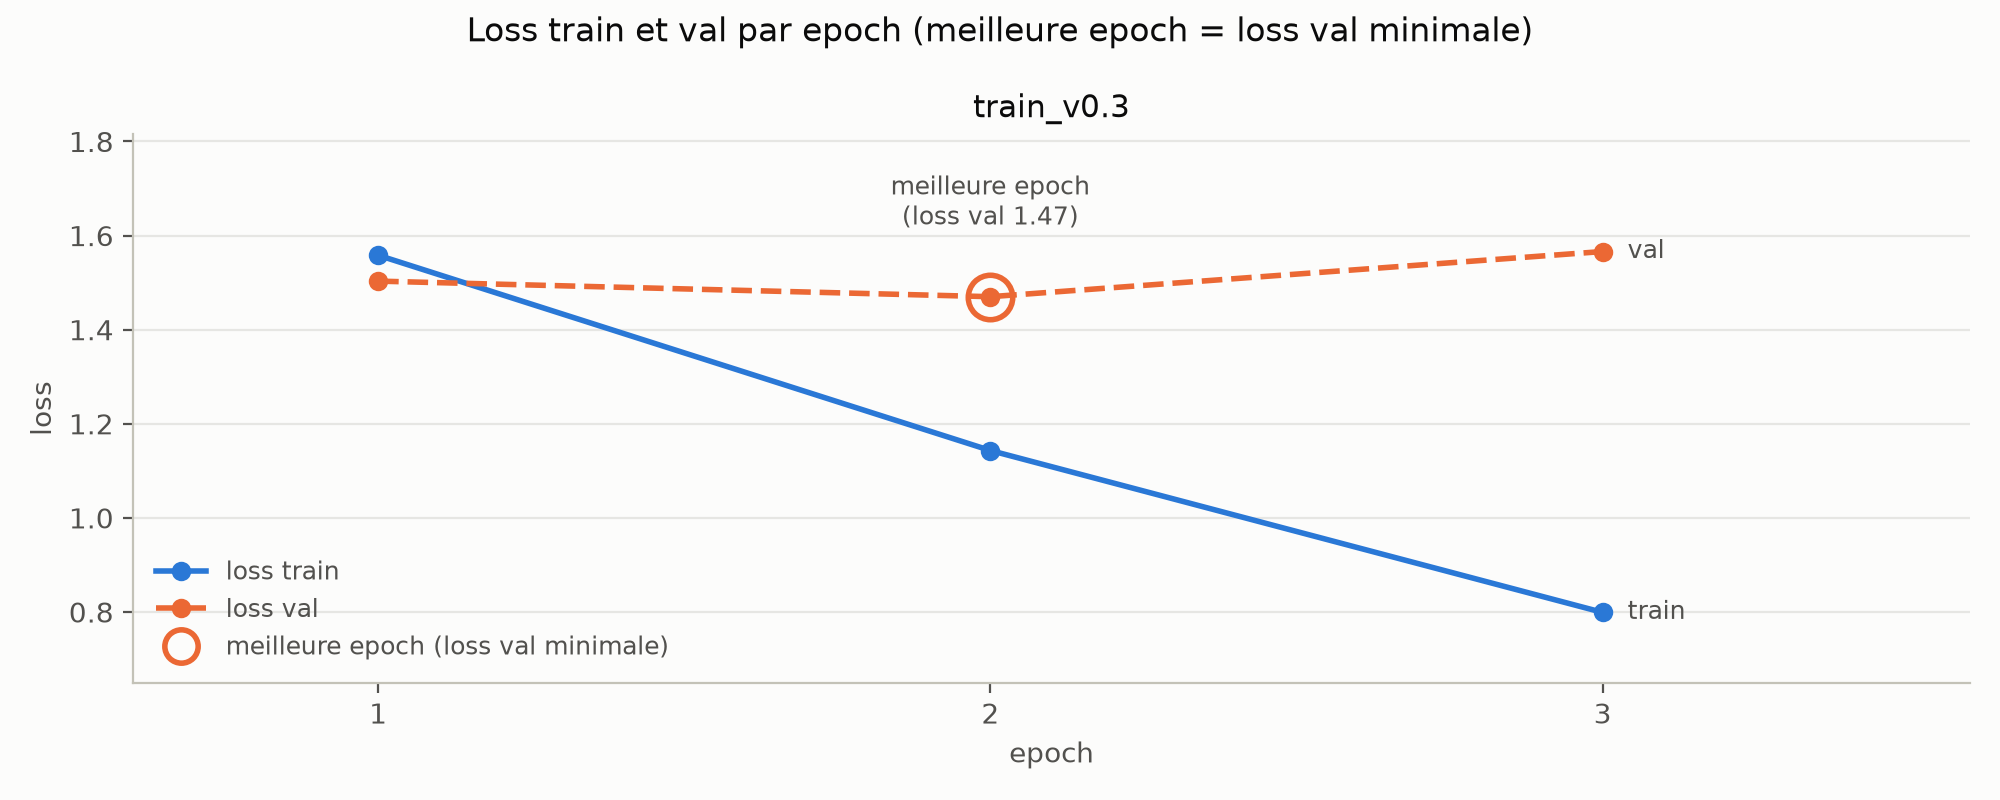

In [7]:
from src.training.plot_losses import plot_loss_history, plot_training_run

run_dir = RESULTS / RUN
fine = (run_dir / "historique_pas.csv").exists() and (run_dir / "historique_val.csv").exists()
png = RESULTS / f"courbe_resume_{RUN}.png"
if fine:
    plot_training_run(str(run_dir), str(png), f"Loss par pas d'optimisation ({RUN})")
else:
    plot_loss_history([(RUN, str(run_dir / "historique_loss.csv"))], str(png))  # pas d'historique fin : courbe par epoch
print(f"courbe {'par pas' if fine else 'par epoch'} enregistrée dans {png.relative_to(ROOT).as_posix()}")
display(Image(filename=str(png)))

In [8]:
from src.training.plot_losses import find_best_epoch, read_loss_history

history = read_loss_history(str(run_dir / "historique_loss.csv"))
best, last = find_best_epoch(history), history["epochs"][-1]
train_down = all(a > b for a, b in zip(history["loss_train"], history["loss_train"][1:]))
result = json.loads((run_dir / "resultat.json").read_text(encoding="utf-8")) if (run_dir / "resultat.json").exists() else {}
accuracy = json.loads((RESULTS / EVAL_LORA).read_text(encoding="utf-8"))["accuracy"]
best_text = f"meilleur pas {result.get('meilleur_pas')}" if fine else f"meilleure epoch {result.get('meilleure_epoch')}"
stop = f"Arrêt : {result['raison_arret']}, {best_text}." if result else "Pas de `resultat.json` pour ce run (ancien format)."
display(Markdown(f"""**Lecture.** {'Un point de la loss val = une mesure.' if fine else 'Un point = une epoch.'} La loss train {'descend toujours' if train_down else 'ne descend pas toujours'} ; la loss val descend jusqu'à l'epoch {best} {'puis remonte' if best < last else "sans remonter pour l'instant"}. C'est un signe de surapprentissage, mais une indication, pas une preuve : {len(history['epochs'])} points, un seul run. {stop}

**Loss et verdict.** La loss val mesure le texte entier (verdict + feedback), pas seulement le verdict. Une loss val qui remonte n'empêche pas un bon verdict : l'évaluation du verdict (exactitude {accuracy:.0%}) a été faite avec l'adaptateur retenu, celui du meilleur moment."""))

**Lecture.** Un point = une epoch. La loss train descend toujours ; la loss val descend jusqu'à l'epoch 2 puis remonte. C'est un signe de surapprentissage, mais une indication, pas une preuve : 3 points, un seul run. Pas de `resultat.json` pour ce run (ancien format).

**Loss et verdict.** La loss val mesure le texte entier (verdict + feedback), pas seulement le verdict. Une loss val qui remonte n'empêche pas un bon verdict : l'évaluation du verdict (exactitude 92%) a été faite avec l'adaptateur retenu, celui du meilleur moment.

In [9]:
from src.training.plot_losses import format_run_row

table = {}  # version -> colonnes de comparaison_runs.md
for line in (RESULTS / "comparaison_runs.md").read_text(encoding="utf-8").splitlines()[2:]:
    columns = [c.strip() for c in line.strip().strip("|").split("|")]
    table[columns[0]] = columns
if "v1.0" not in table and (RESULTS / "train_v1.0" / "historique_loss.csv").exists():  # run final copié dans le dépôt
    row = format_run_row({"version": "v1.0", "output_dir": str(RESULTS / "train_v1.0")})
    table["v1.0"] = [c.strip() for c in row.strip("|").split("|")]
protocoles = {"v0.2": ("essai 1 (v0.2)", "lot de 1 x 8 accumulations, mesure par epoch"),
              "v0.3": ("essai 2 (v0.3)", "idem, sur Colab"),
              "v1.0": ("run final (v1.0)", f"vrai lot de 8, mesure de la loss val tous les {FINAL_PLAN['eval_every']} pas")}
lines = ["| Essai | Matériel | Learning rate | Protocole | Loss val par epoch | Meilleure epoch |", "|---|---|---|---|---|---|"]
for version, (name, protocole) in protocoles.items():
    c = table.get(version, ["", "A100", "sera ajouté", "sera ajouté", "", "sera ajouté"])  # ligne discrète tant que le run final n'est pas dans le dépôt
    gpu = "Colab A100" if "A100" in c[1] else c[1]
    lines.append(f"| {name} | {gpu} | {c[2]} | {protocole} | {c[5]} | {c[3]} |")
display(Markdown("\n".join(lines)))
print("Ce sont des essais successifs, pas un même modèle qui progresse : seul le protocole change.")

| Essai | Matériel | Learning rate | Protocole | Loss val par epoch | Meilleure epoch |
|---|---|---|---|---|---|
| essai 1 (v0.2) | RTX 4070 | 2e-4 | lot de 1 x 8 accumulations, mesure par epoch | 1.4756 / 1.4823 / 1.5864 | 1 |
| essai 2 (v0.3) | Colab A100 | 1e-4 | idem, sur Colab | 1.5032 / 1.4701 / 1.5661 | 2 |
| run final (v1.0) | Colab A100 | sera ajouté | vrai lot de 8, mesure de la loss val tous les 25 pas | sera ajouté | sera ajouté |

Ce sont des essais successifs, pas un même modèle qui progresse : seul le protocole change.


## 3. Pourquoi ces réglages

Chaque réglage vient d'une contrainte (matériel, données) ou d'une observation. Ceux qui sont seulement usuels, ou pas testés, sont dits comme tels. Les nombres ci-dessous sont lus dans les fichiers du run et dans `src/training`.

In [10]:
import math
from transformers import AutoTokenizer
from src.training.dataset import MAX_LENGTH, load_split, token_lengths
from src.training.plot_losses import read_csv_columns

cfg = json.loads((RESULTS / RUN / "config.json").read_text(encoding="utf-8"))
batch = cfg.get("batch_size_effectif", cfg["accumulation_steps"])  # les anciens config.json n'ont pas cette clé
n_train = len(load_split("train"))
steps = lambda b: math.ceil(n_train / b)  # corrections par epoch pour un lot de b
seconds = {v: read_csv_columns(RESULTS / f"train_{v}" / "historique_loss.csv")["secondes"] for v in ("v0.2", "v0.3")}
per_example = {v: sum(s) / len(s) / n_train for v, s in seconds.items()}  # secondes par exemple, moyenne sur les epochs
tokenizer = AutoTokenizer.from_pretrained("Qwen/Qwen2.5-3B-Instruct")
longest = max(token_lengths(load_split("train") + load_split("val"), tokenizer))
display(Markdown(f"""**Ce que la mémoire impose.** En 4 bits, le modèle de 6 Go tient dans environ 2 Go. Sur la RTX 4070 : environ {per_example['v0.2']:.0f} s par exemple, contre environ {per_example['v0.3']:.1f} s sur A100 (moyennes calculées depuis les durées d'epoch). La 4070 était limitée par sa mémoire (12 Go, GPU plein pendant l'entraînement : un constat, pas la mesure de la cause). D'où le passage à Colab. Sur l'A100 (80 Go), un lot de {batch} conversations passe en parallèle ; avec moins de mémoire, 4 x 2 ou 1 x 8 donne le même effet.

**Ce que les données imposent.** Il y a {n_train} exemples d'entraînement. Un lot de {batch} est un compromis entre une correction stable et assez de corrections : {steps(batch)} par epoch, contre {steps(batch // 2)} avec un lot de {batch // 2} et {steps(batch * 2)} avec un lot de {batch * 2}. {batch} n'a pas été comparé à {batch // 2} ou à {batch * 2} ici (non testé ici). Avec un lot de 32, il ne resterait que {steps(32)} corrections par epoch : on n'a pas testé si c'est suffisant.

`max_length` vaut {MAX_LENGTH} : un arrondi (puissance de 2) au-dessus de la conversation la plus longue mesurée, {longest} tokens. Une valeur plus grande coûterait de la mémoire sans rien apporter tant qu'aucune conversation ne la dépasse."""))

**Ce que la mémoire impose.** En 4 bits, le modèle de 6 Go tient dans environ 2 Go. Sur la RTX 4070 : environ 18 s par exemple, contre environ 1.5 s sur A100 (moyennes calculées depuis les durées d'epoch). La 4070 était limitée par sa mémoire (12 Go, GPU plein pendant l'entraînement : un constat, pas la mesure de la cause). D'où le passage à Colab. Sur l'A100 (80 Go), un lot de 8 conversations passe en parallèle ; avec moins de mémoire, 4 x 2 ou 1 x 8 donne le même effet.

**Ce que les données imposent.** Il y a 885 exemples d'entraînement. Un lot de 8 est un compromis entre une correction stable et assez de corrections : 111 par epoch, contre 222 avec un lot de 4 et 56 avec un lot de 16. 8 n'a pas été comparé à 4 ou à 16 ici (non testé ici). Avec un lot de 32, il ne resterait que 28 corrections par epoch : on n'a pas testé si c'est suffisant.

`max_length` vaut 4096 : un arrondi (puissance de 2) au-dessus de la conversation la plus longue mesurée, 3638 tokens. Une valeur plus grande coûterait de la mémoire sans rien apporter tant qu'aucune conversation ne la dépasse.

In [11]:
from src.training.model import LORA_TARGET_MODULES
from src.training.plot_losses import find_best_epoch, read_loss_history
from src.training.train import LEARNING_RATE

fmt_lr = lambda value: f"{value:.0e}".replace("e-0", "e-")  # 2e-4 plutôt que 0.0002
histories = {v: read_loss_history(str(RESULTS / f"train_{v}" / "historique_loss.csv")) for v in ("v0.2", "v0.3")}
best = sorted(find_best_epoch(h) for h in histories.values())  # meilleure epoch de chaque essai
per_epoch = steps(batch) / FINAL_PLAN["eval_every"]  # mesures de la loss val par epoch
lr_b = json.loads((RESULTS / "train_v0.3" / "config.json").read_text(encoding="utf-8"))["learning_rate"]
display(Markdown(f"""**Ce que l'on a observé.** {cfg['epochs']} epochs : valeur de départ. La loss val atteint son minimum à l'epoch {best[0]} ou {best[1]} puis remonte : {cfg['epochs']} epochs suffisent pour voir le minimum et la remontée (ni moins ni plus d'epochs n'ont été essayés). Mesure tous les {FINAL_PLAN['eval_every']} pas : environ {per_epoch:.0f} mesures par epoch (courbe assez fine ; chaque mesure coûte du temps). Patience {FINAL_PLAN['patience']} : arrêt après environ {FINAL_PLAN['patience'] / per_epoch:.1f} epoch sans progrès ; choix non testé. Learning rate : {fmt_lr(LEARNING_RATE)} dans l'essai 1, {fmt_lr(lr_b)} dans l'essai 2, avec une loss val minimale de {min(histories['v0.2']['loss_val']):.3f} et {min(histories['v0.3']['loss_val']):.3f} : pas de différence nette, et un seul essai chacun.

**Valeurs usuelles, non comparées ici.** Rang {cfg['lora_rank']}, alpha {cfg['lora_alpha']}, dropout {cfg['lora_dropout']}, {len(LORA_TARGET_MODULES)} types de couches adaptées : ce sont des valeurs courantes en LoRA, jamais comparées ici. C'est une piste d'amélioration."""))

**Ce que l'on a observé.** 3 epochs : valeur de départ. La loss val atteint son minimum à l'epoch 1 ou 2 puis remonte : 3 epochs suffisent pour voir le minimum et la remontée (ni moins ni plus d'epochs n'ont été essayés). Mesure tous les 25 pas : environ 4 mesures par epoch (courbe assez fine ; chaque mesure coûte du temps). Patience 4 : arrêt après environ 0.9 epoch sans progrès ; choix non testé. Learning rate : 2e-4 dans l'essai 1, 1e-4 dans l'essai 2, avec une loss val minimale de 1.476 et 1.470 : pas de différence nette, et un seul essai chacun.

**Valeurs usuelles, non comparées ici.** Rang 16, alpha 32, dropout 0.05, 7 types de couches adaptées : ce sont des valeurs courantes en LoRA, jamais comparées ici. C'est une piste d'amélioration.

## 4. Limites et suite

- `val` est étroit : très peu de questions, des exemples très corrélés, et il a servi à choisir l'adaptateur retenu. Les chiffres sont optimistes.
- Les étiquettes (verdicts et feedbacks du dataset) ont été générées par deux LLM. Elles n'ont pas été relues ligne à ligne.
- Un seul entraînement par réglage : on ne sépare pas un vrai effet du hasard.
- Le test indépendant est celui du bloc d'évaluation, pas encore fusionné. C'est lui qui donnera le chiffre à retenir.
- Le modèle fait 3 milliards de paramètres. Un modèle plus gros n'a pas été essayé.

**Pour refaire** (GPU de 40 Go ou plus ; avec moins de mémoire, remplacer `--batch-size 8 --accumulation-steps 1` par `--batch-size 4 --accumulation-steps 2`) :

```
pip install -r requirements-qlora.txt
python -m src.training.run_training --epochs 3 --learning-rate 1e-4 --patience 4 --eval-every 25 --batch-size 8 --accumulation-steps 1 --output-dir adapters/v1.0
python -m src.training.evaluate_verdicts --adapter none --split val --output eval_base.json
python -m src.training.evaluate_verdicts --adapter adapters/v1.0/best --split val --output eval_lora.json
python -m src.training.export_examples --adapter adapters/v1.0/best --eval-base eval_base.json --eval-lora eval_lora.json --output exemples.json
```

Le code est dans `src/training/` (`dataset.py`, `model.py`, `train.py`, `run_training.py`, `evaluate_verdicts.py`, `plot_losses.py`).